In [1]:
# Interfaz
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
import pandas as pd
%matplotlib widget
%config InlineBackend.figure_format = 'svg'
from scipy.linalg import solve_toeplitz
#========================================================================================================================================
# Variables generales
#========================================================================================================================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'
color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
line_width = 1.5
#==================

NMF

In [2]:
señales       = np.loadtxt("Señales Repositorio II Resampleadas/Male_A_110Hz_large.txt", delimiter="\t")
tiempos_      = señales[:, 0]
señal_speech_ = señales[:, 1]
señal_flujo_  = señales[:, 2]
señal_dflujo_ = señales[:, 3]
señal_area_   = señales[:, 4]
señal_darea_  = señales[:, 5]
to = 750
tf = 800
fs_r = 8000
no = int(np.round(to *fs_r/1000)) 
nf = int(np.round(tf * fs_r/1000))
tiempos       = tiempos_[no:nf] - 750
t0_analisis = 5 #ms 
tf_analisis = 45#ms
mascara_tiempos = (tiempos >= t0_analisis) & (tiempos <= tf_analisis)
tiempos_analisis = tiempos[mascara_tiempos]

señal_MBK  = señal_speech_[no:nf]
señal_flujo   = señal_flujo_[no:nf]
señal_dflujo   = señal_dflujo_[no:nf]
señal_area    = señal_area_[no:nf]
señal_darea   = señal_darea_[no:nf]
señal_darea = señal_darea/max(abs(señal_darea))

In [3]:
resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK,
                                    dEGG = señal_darea,
                                    tiempos=tiempos,
                                    mascara_tiempos=mascara_tiempos,
                                    fs=fs_r
                                    )
i = resultado_NMF_speech.n_iteraciones

In [39]:
def _resolver_toeplitz(W):
    W = W**(2/0.55)
    W_  = np.concatenate((W, np.flip(W)[1:-1]))
    r_W = np.fft.ifft(W_).real
    a_  = solve_toeplitz(
        (r_W[0:12], r_W[0:12]),
        r_W[1:12+1]
    )
    a_W= np.concatenate(([1.0], -a_))
    num      = np.zeros(len(a_W))
    num[0]   = 1
    ceros_W,polos_W,_ = sig.tf2zpk(num,a_W)
    polos_originales = polos_W
    polos_ = [p for p in polos_W if not ( ((p.real > 0.0) and(p.imag == 0.0))  or ((p.real > 0.0) and (np.abs(p) < 0.8)))]


    b,a = sig.zpk2tf(np.zeros(len(polos_)),polos_,k=1)
    a_W = a
    polos_W = polos_
    #ceros_W = ceros_W[:len(polos_W)-1]
    return a_W,polos_originales,ceros_W

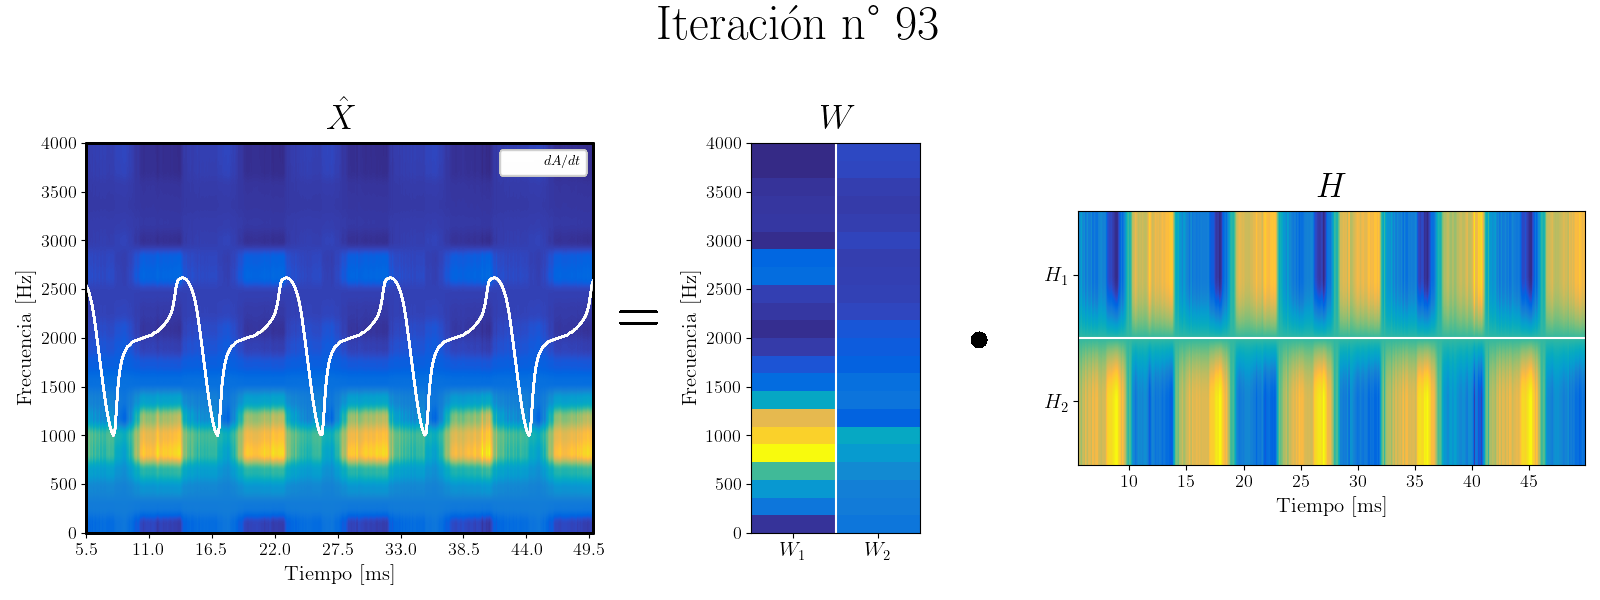

In [86]:
# Crear figura y ejes una sola vez
fig_, ax_ = plt.subplots(
1, 3,
figsize=(16, 6),
gridspec_kw={'width_ratios': [30, 10, 30]}
)
plt.subplots_adjust(wspace=0.55)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

cmap = Funciones.parula_map
for i in range(resultado_NMF_speech.n_iteraciones+1):
#Limpiar cada eje antes de redibujar
    for a in ax_:
        a.cla()

    # ============================================================
    # 1. Matriz X
    # ============================================================
    #i = 1
    ax_[0].imshow(resultado_NMF_speech.proceso_espectrograma_aprox[i],
        cmap=cmap, origin='lower', aspect='auto',
        extent=[resultado_NMF_speech.to_espectrograma,
                resultado_NMF_speech.tf_espectrograma,
                resultado_NMF_speech.fo_espectrograma,
                resultado_NMF_speech.ff_espectrograma]
    )
    ax_[0].set_title(r'$\hat{X}$', fontsize=25, pad=10)
    ax_[0].set_xlabel('Tiempo [ms]', fontsize=15)
    ax_[0].set_ylabel('Frecuencia [Hz]', fontsize=15)
    ax_[0].tick_params(axis='x', labelsize=13)
    ax_[0].tick_params(axis='y', labelsize=13)
    ax_da = ax_[0].twinx()
    ax_da.plot(tiempos,señal_darea,color='white', label=r"$dA/dt$", linewidth=line_width)
    ax_da.legend(loc=legend_loc)
    ax_da.set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
    ax_da.set_ylim([-2,2])
    ax_da.set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma, resultado_NMF_speech.duracion_ventana))
    ax_da.set_yticks([])
    # ============================================================
    # 2. Matriz W
    # ============================================================

    matriz_w = np.column_stack((resultado_NMF_speech.proceso_W1[i], resultado_NMF_speech.proceso_W2[i]))

    ax_[1].imshow(matriz_w, cmap=cmap, origin='lower', aspect='auto',
                    extent=[0, 2,
                            resultado_NMF_speech.fo_espectrograma,
                            resultado_NMF_speech.ff_espectrograma])
    ax_[1].set_title(r'$W$', fontsize=25, pad=10)
    ax_[1].set_ylabel('Frecuencia [Hz]', fontsize=15)
    ax_[1].axvline(1, color='white', linewidth=1.5)
    ax_[1].set_xticks([0.5, 1.5])
    ax_[1].set_xticklabels([r'$W_1$', r'$W_2$'], fontsize=15)
    ax_[1].tick_params(axis='y', labelsize=13)
    # ============================================================
    # 3. Matriz H
    # ============================================================
    matriz_h = np.vstack((resultado_NMF_speech.proceso_H2[i],
                            resultado_NMF_speech.proceso_H1[i]))
    ax_[2].imshow(matriz_h, cmap=cmap, origin='lower', aspect='auto',
                    extent=[resultado_NMF_speech.to_espectrograma,
                            resultado_NMF_speech.tf_espectrograma, 0, 2])
    ax_[2].set_title(r'$H$', fontsize=25, pad=10)
    ax_[2].set_yticks([0.5, 1.5])
    ax_[2].set_yticklabels([r'$H_2$', r'$H_1$'], fontsize=15)
    ax_[2].axhline(1, color='white', linewidth=1.5)
    ax_[2].set_box_aspect(0.5)
    ax_[2].set_xlabel('Tiempo [ms]', fontsize=15)
    ax_[2].tick_params(axis='x', labelsize=13)
    # Texto entre figuras
    fig_.text(0.40, 0.47, r'$=$', fontsize=45, ha='center', va='center')
    fig_.text(0.62, 0.47, r'$\cdot$', fontsize=110, ha='center', va='center')

    # Título general
    fig_.suptitle(f'Iteración n° {i}', fontsize=35, y=0.99)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.subplots_adjust(wspace=0.4)   # aumenta el espacio entre columnas
    plt.savefig(f'Animacion presentacion/Animacion NMF/{i}.pdf', bbox_inches='tight')

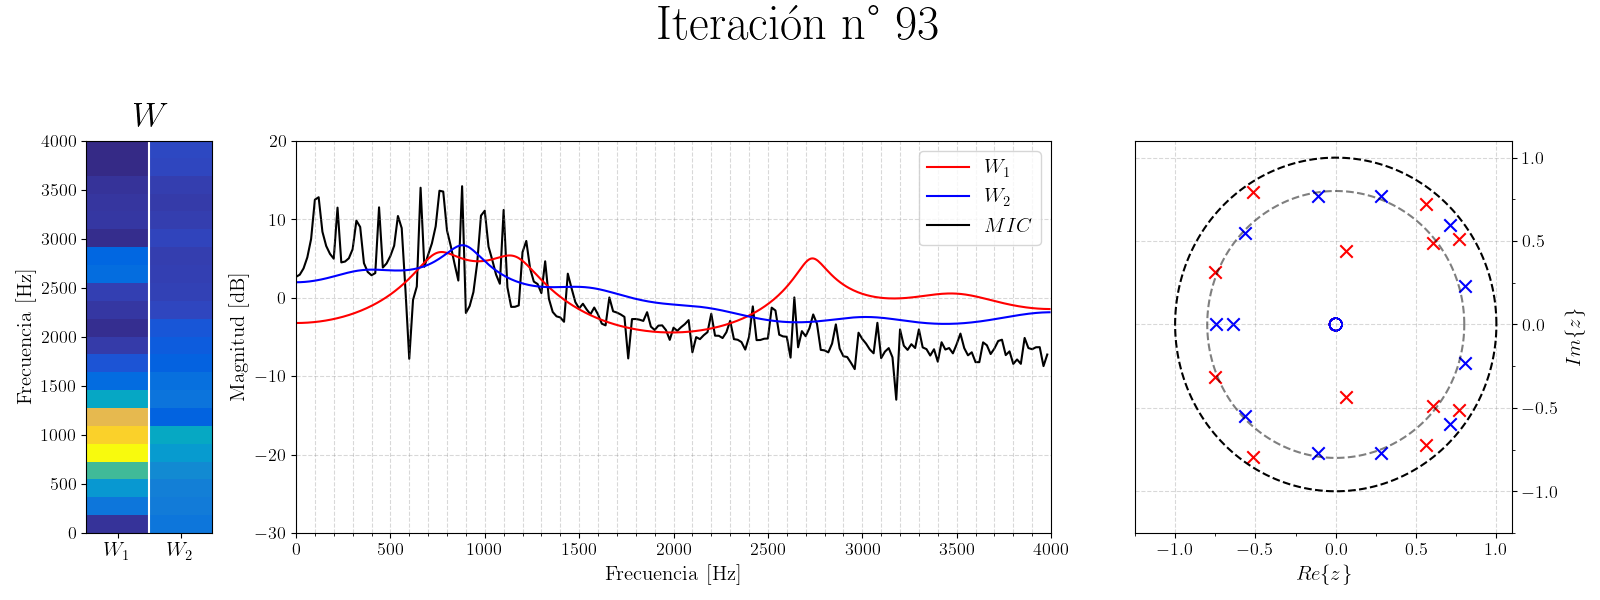

In [88]:
# Crear figura y ejes una sola vez
fig_, ax_ = plt.subplots(1,3,
figsize=(16, 6),
gridspec_kw={'width_ratios': [10, 60,30]}
)
plt.subplots_adjust(wspace=0.20)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

cmap = Funciones.parula_map
theta = np.linspace(0, 2*np.pi, 200)
for i in range(resultado_NMF_speech.n_iteraciones+1):
        for a in ax_:
                a.cla()

#i = 0
        matriz_w = np.column_stack((resultado_NMF_speech.proceso_W1[i], resultado_NMF_speech.proceso_W2[i]))

        ax_[0].imshow(matriz_w, cmap=cmap, origin='lower', aspect='auto',
                        extent=[0, 2,
                                resultado_NMF_speech.fo_espectrograma,
                                resultado_NMF_speech.ff_espectrograma])
        ax_[0].set_title(r'$W$', fontsize=25, pad=10)
        ax_[0].set_ylabel('Frecuencia [Hz]', fontsize=15)
        ax_[0].axvline(1, color='white', linewidth=1.5)
        ax_[0].set_xticks([0.5, 1.5])
        ax_[0].set_xticklabels([r'$W_1$', r'$W_2$'], fontsize=15)
        ax_[0].tick_params(axis='y', labelsize=13)
        fs_r = 8000
        # ------------- Respuesta en frecuencia
        a_W1,polos_W1,ceros_W1 =_resolver_toeplitz(resultado_NMF_speech.proceso_W1[i])
        a_W2,polos_W2,ceros_W2 =_resolver_toeplitz(resultado_NMF_speech.proceso_W2[i])

        theta = np.linspace(0, 2*np.pi, 200)
        fftseñal, fseñal = Funciones.FFT(señal_MBK, fs_r)
        fw1,hw1 = sig.freqz([1],a_W1,fs=fs_r)
        fw2,hw2 = sig.freqz([1],a_W2,fs=fs_r)
        ax_[1].plot(fw1, 10*np.log10(np.abs(hw1)), label=r'$W_1$',color=color1)
        ax_[1].plot(fw2, 10*np.log10(np.abs(hw2)), label=r'$W_2$', color=color2)
        ax_[1].plot(fseñal, 10*np.log10(np.abs(fftseñal)), label=r'$MIC$', color=color3, zorder=-1)
        ax_[1].set_xlim(0,fs_r/2)
        ax_[1].set_xticks(np.arange(0, fs_r/2, 100), minor=True)
        ax_[1].tick_params(axis='x', labelsize=13)
        ax_[1].tick_params(axis='y', labelsize=13)
        ax_[1].grid(True, linestyle='dashed', color='gray', alpha=0.3, which='both')
        ax_[1].set_xlabel('Frecuencia [Hz]', fontsize=15)
        ax_[1].set_ylabel('Magnitud [dB]', fontsize=15)
        ax_[1].set_ylim([-30,20])
        ax_[1].legend(loc='upper right', fontsize=15)

        ax_[2].plot(np.cos(theta), np.sin(theta), 'k--', alpha=1)
        ax_[2].plot(0.8*np.cos(theta), 0.8*np.sin(theta), 'k--', alpha=0.5)
        ax_[2].yaxis.tick_right()
        ax_[2].yaxis.set_label_position("right")
        ax_[2].scatter(np.real(ceros_W1), np.imag(ceros_W1),s=80, facecolors='none', edgecolors=color1, label='Ceros')
        ax_[2].scatter(np.real(polos_W1), np.imag(polos_W1),s=80, marker='x', color=color1, label='Polos')
        ax_[2].scatter(np.real(ceros_W1), np.imag(ceros_W1),s=80, facecolors='none', edgecolors=color2, label='Ceros')
        ax_[2].scatter(np.real(polos_W2), np.imag(polos_W2),s=80, marker='x', color=color2, label='Polos')
        ax_[2].set_xticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax_[2].set_yticks(np.arange(-1.25,1.25,0.25), minor=True)
        ax_[2].set_ylabel(r"$Im\{z\}$", fontsize=15)
        ax_[2].set_xlabel(r"$Re\{z\}$", fontsize=15)
        ax_[2].tick_params(axis='x', labelsize=13)
        ax_[2].tick_params(axis='y', labelsize=13)
        ax_[2].grid(True, linestyle='dashed', color='gray', alpha=0.3)
        # Título general
        fig_.suptitle(f'Iteración n° {i}', fontsize=35, y=0.99)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.subplots_adjust(wspace=0.20)   # aumenta el espacio entre columnas
        plt.savefig(f'Animacion presentacion/Animacion NMF W/{i}.pdf', bbox_inches='tight')


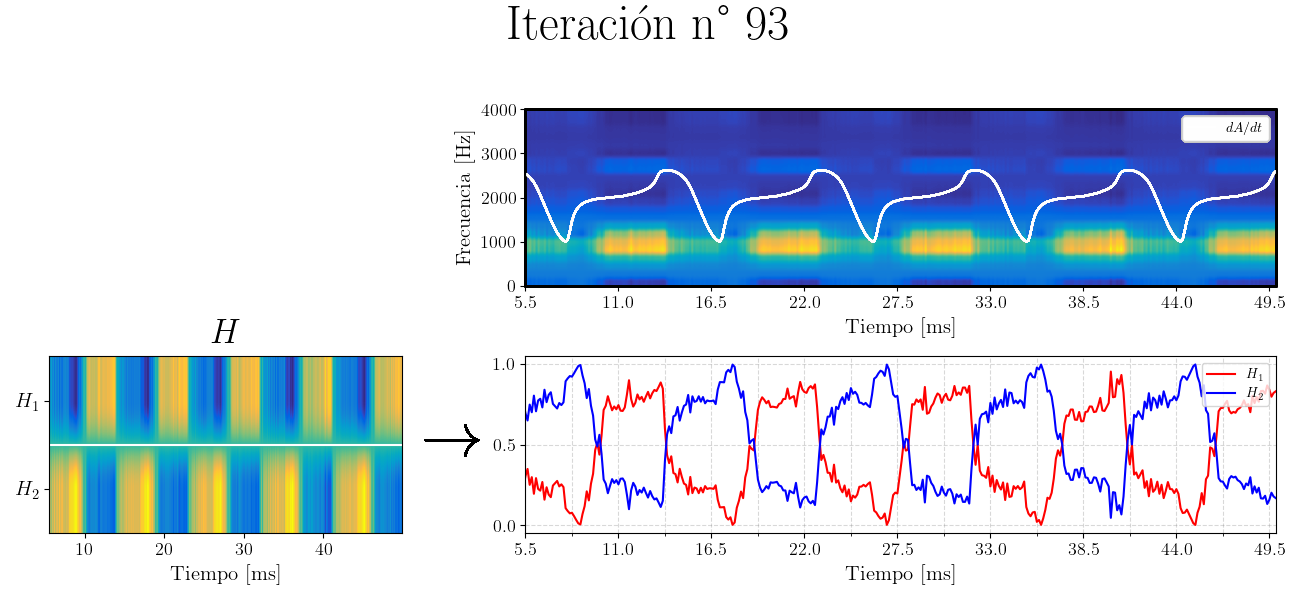

In [143]:
fig_, ax_ = plt.subplots(2,2,
figsize=(13, 6),
gridspec_kw={'width_ratios': [0.5,1]}
)
plt.subplots_adjust(hspace=0.30)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']


for i in range(resultado_NMF_speech.n_iteraciones+1):
        for i_ in range(0,2):
                for j in range(0,2):
                        ax_[i_][j].cla()
#i = 0
        ax_[0,0].axis('off') 
        matriz_h = np.vstack((resultado_NMF_speech.proceso_H2[i],
                                resultado_NMF_speech.proceso_H1[i]))
        ax_[1][0].imshow(matriz_h, cmap=cmap, origin='lower', aspect='auto',
                        extent=[resultado_NMF_speech.to_espectrograma,
                                resultado_NMF_speech.tf_espectrograma, 0, 2])
        ax_[1][0].set_title(r'$H$', fontsize=25, pad=10)
        ax_[1][0].set_yticks([0.5, 1.5])
        ax_[1][0].set_yticklabels([r'$H_2$', r'$H_1$'], fontsize=15)
        ax_[1][0].axhline(1, color='white', linewidth=1.5)
        ax_[1][0].set_box_aspect(0.5)
        ax_[1][0].set_xlabel('Tiempo [ms]', fontsize=15)
        ax_[1][0].tick_params(axis='x', labelsize=13);


        ax_[0][1].imshow(resultado_NMF_speech.proceso_espectrograma_aprox[i],
                        cmap=cmap,
                        origin='lower',
                        aspect='auto',
                        extent=[resultado_NMF_speech.to_espectrograma, resultado_NMF_speech.tf_espectrograma,
                                resultado_NMF_speech.fo_espectrograma, resultado_NMF_speech.ff_espectrograma])
        ax_[0][1].set_ylabel('Frecuencia [Hz]', fontsize=15)
        ax_[0][1].set_xlabel("Tiempo [ms]", fontsize=15)
        ax_[0][1].tick_params(axis='x', labelsize=13);
        ax_[0][1].tick_params(axis='y', labelsize=13);
        ax_da = ax_[0][1].twinx()
        ax_da.plot(tiempos,señal_darea,color='white', label=r"$dA/dt$", linewidth=line_width)
        ax_da.legend(loc=legend_loc)
        ax_da.set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
        ax_da.set_ylim([-2,2])
        ax_da.set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma, resultado_NMF_speech.duracion_ventana))
        ax_da.set_yticks([])


        ax_[1][1].plot(resultado_NMF_speech.tiempos_espectrograma,resultado_NMF_speech.proceso_H1[i],color=color1,label=r'$H_1$')
        ax_[1][1].plot(resultado_NMF_speech.tiempos_espectrograma,resultado_NMF_speech.proceso_H2[i],color=color2,label=r'$H_2$')
        ax_[1][1].set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
        ax_[1][1].set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma,resultado_NMF_speech.duracion_ventana))
        ax_[1][1].set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma,resultado_NMF_speech.duracion_ventana/2),minor=True)
        ax_[1][1].grid(True,linestyle='dashed',color='gray',alpha=0.3,which='both')
        ax_[1][1].legend(loc=legend_loc)
        ax_[1][1].set_xlabel('Tiempo [ms]', fontsize=15);
        ax_[1][1].tick_params(axis='x', labelsize=13);
        ax_[1][1].tick_params(axis='y', labelsize=13);

        fig_.suptitle(f'Iteración n° {i}', fontsize=35, y=0.99)

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.subplots_adjust(hspace=0.40,wspace=0.20)   # aumenta el espacio entre columnas
        fig_.text(0.35, 0.25, r'$\rightarrow$', fontsize=45, ha='center', va='center')
        plt.savefig(f'Animacion presentacion/Animación NMF H/{i}.pdf', bbox_inches='tight')

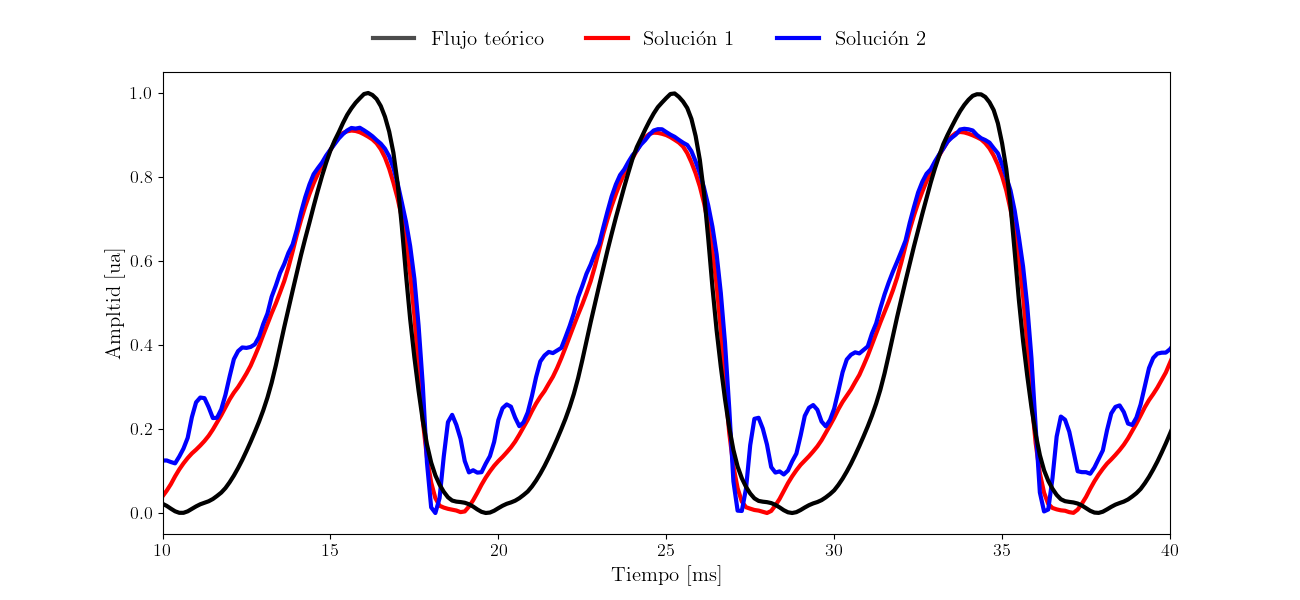

In [7]:
fig_, ax_ = plt.subplots(
figsize=(13, 6))
plt.subplots_adjust(hspace=0.30)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

f1 = Funciones.Normalizar(resultado_NMF_speech.flujo1)
se,sr,t= Funciones.Sincronizar2(f1,Funciones.Normalizar(señal_flujo[mascara_tiempos]),tiempos_analisis)
ax_.plot(t,se,color=color1,label=r'Solución 1',linewidth=3)

f2 = Funciones.Normalizar(resultado_NMF_speech.flujo2)
se,sr,t= Funciones.Sincronizar2(f2,Funciones.Normalizar(señal_flujo[mascara_tiempos]),tiempos_analisis)
ax_.plot(t,se,color=color2,label=r'Solución 2',linewidth=3)

ax_.plot(tiempos_analisis,Funciones.Normalizar(señal_flujo[mascara_tiempos]),color='k',label=r'Solución 2',linewidth=3)
ax_.set_xlim([10,40])
ax_.set_xlabel('Tiempo [ms]', fontsize=15);
ax_.set_ylabel('Ampltid [ua]', fontsize=15);
ax_.tick_params(axis='x', labelsize=13);
ax_.tick_params(axis='y', labelsize=13);
handles = [
    plt.Line2D([0], [0], color='k', alpha=0.7, label='Flujo teórico',linewidth=3),
    plt.Line2D([0], [0], color=color1, label='Solución 1',linewidth=3),
    plt.Line2D([0], [0], color=color2, label='Solución 2',linewidth=3),
]
'''
fig.legend(handles=handles,
        loc='upper center',
        ncol=3,
        frameon=True,
        fontsize=11,
        bbox_to_anchor=(0.5,0.96));
'''
fig_.legend(handles=handles,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.98),  # ← misma altura, más a la derecha
        ncol=3,frameon=False,fontsize=15);
plt.savefig(f'Animacion presentacion/resultado_NMF.pdf', bbox_inches='tight')

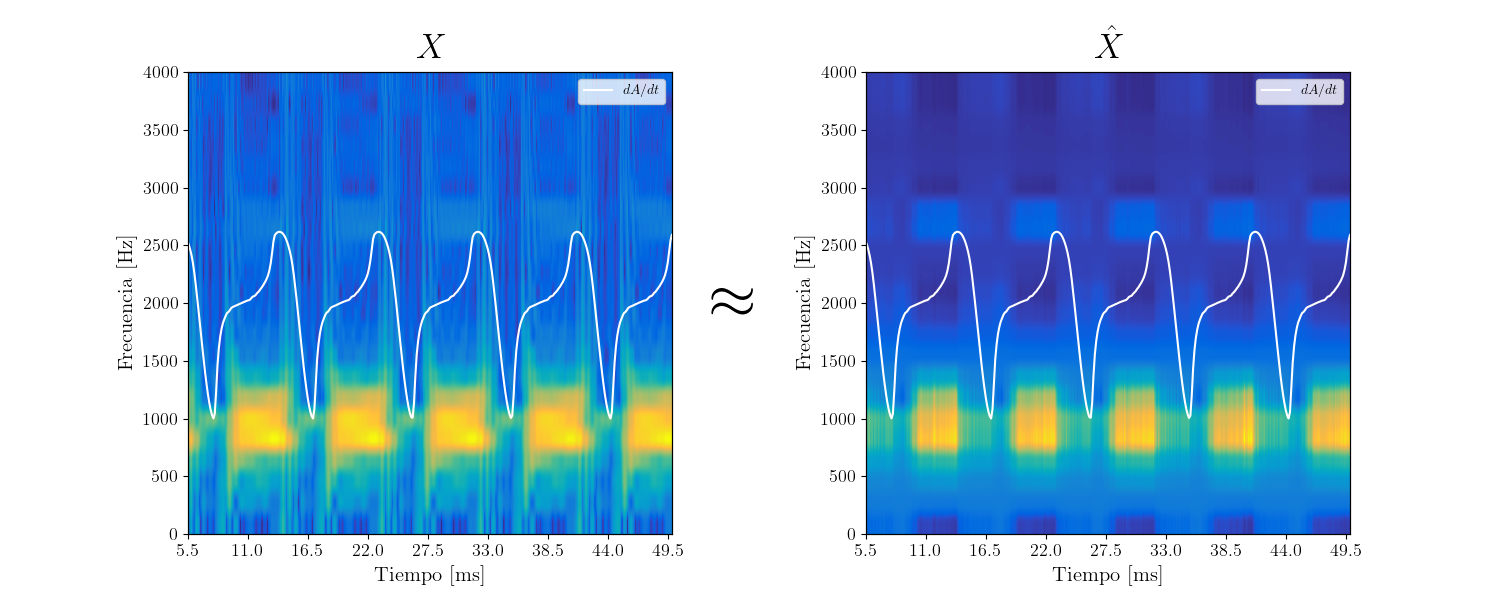

In [131]:
fig_, ax_ = plt.subplots(1,2,
figsize=(15, 6))
plt.subplots_adjust(wspace=0.40)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

#i = 1
ax_[0].imshow(resultado_NMF_speech.espectrograma,
    cmap=cmap, origin='lower', aspect='auto',
    extent=[resultado_NMF_speech.to_espectrograma,
            resultado_NMF_speech.tf_espectrograma,
            resultado_NMF_speech.fo_espectrograma,
            resultado_NMF_speech.ff_espectrograma]
)
ax_[0].set_title(r'$X$', fontsize=25, pad=10)
ax_[0].set_xlabel('Tiempo [ms]', fontsize=15)
ax_[0].set_ylabel('Frecuencia [Hz]', fontsize=15)
ax_[0].tick_params(axis='x', labelsize=13)
ax_[0].tick_params(axis='y', labelsize=13)
ax_da = ax_[0].twinx()
ax_da.plot(tiempos,señal_darea,color='white', label=r"$dA/dt$", linewidth=line_width)
ax_da.legend(loc=legend_loc)
ax_da.set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
ax_da.set_ylim([-2,2])
ax_da.set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma, resultado_NMF_speech.duracion_ventana))
ax_da.set_yticks([]);

ax_[1].imshow(resultado_NMF_speech.proceso_espectrograma_aprox[i],
    cmap=cmap, origin='lower', aspect='auto',
    extent=[resultado_NMF_speech.to_espectrograma,
            resultado_NMF_speech.tf_espectrograma,
            resultado_NMF_speech.fo_espectrograma,
            resultado_NMF_speech.ff_espectrograma]
)
ax_[1].set_title(r'$\hat{X}$', fontsize=25, pad=10)
ax_[1].set_xlabel('Tiempo [ms]', fontsize=15)
ax_[1].set_ylabel('Frecuencia [Hz]', fontsize=15)
ax_[1].tick_params(axis='x', labelsize=13)
ax_[1].tick_params(axis='y', labelsize=13)
ax_da = ax_[1].twinx()
ax_da.plot(tiempos,señal_darea,color='white', label=r"$dA/dt$", linewidth=line_width)
ax_da.legend(loc=legend_loc)
ax_da.set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
ax_da.set_ylim([-2,2])
ax_da.set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma, resultado_NMF_speech.duracion_ventana))
ax_da.set_yticks([]);
fig_.text(0.49, 0.5, r'$\approx$', fontsize=45, ha='center', va='center')
plt.savefig(f'Animacion presentacion/aproximacion_NMF.pdf', bbox_inches='tight')

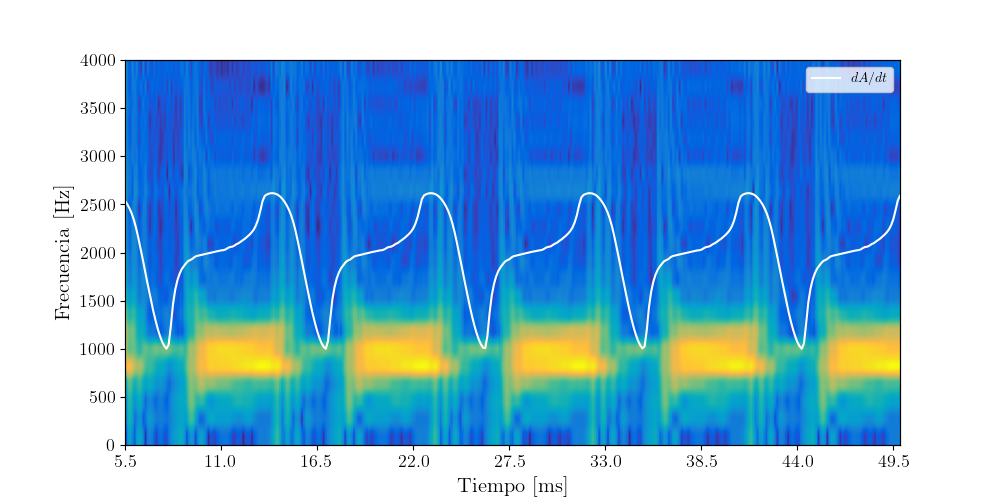

In [137]:
fig_, ax_ = plt.subplots(figsize=(10, 5))
plt.subplots_adjust(wspace=0.40)

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern Roman']

#i = 1
ax_.imshow(resultado_NMF_speech.espectrograma,
    cmap=cmap, origin='lower', aspect='auto',
    extent=[resultado_NMF_speech.to_espectrograma,
            resultado_NMF_speech.tf_espectrograma,
            resultado_NMF_speech.fo_espectrograma,
            resultado_NMF_speech.ff_espectrograma]
)
ax_da = ax_.twinx()
ax_da.plot(tiempos,señal_darea,color='white', label=r"$dA/dt$", linewidth=line_width)
ax_da.legend(loc=legend_loc)
ax_da.set_xlim(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma)
ax_da.set_ylim([-2,2])
ax_da.set_xticks(np.arange(resultado_NMF_speech.to_espectrograma,resultado_NMF_speech.tf_espectrograma, resultado_NMF_speech.duracion_ventana))
ax_da.set_yticks([]);
ax_.set_xlabel('Tiempo [ms]', fontsize=15)
ax_.set_ylabel('Frecuencia [Hz]', fontsize=15)
ax_.tick_params(axis='x', labelsize=13)
ax_.tick_params(axis='y', labelsize=13)
plt.savefig(f'Animacion presentacion/espectrograma nmf original.pdf', bbox_inches='tight')